In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose  import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

import joblib

In [3]:
np.random.seed(42)
n=1000
df=pd.DataFrame({
    "Area":np.random.randint(500,4000,n),
    "Bedrooms":np.random.randint(1,6,n),
    "Bathrooms":np.random.randint(1,5,n),
    "Parking":np.random.randint(0,3,n),
    "Stories":np.random.randint(1,4,n),
    "Location":np.random.choice(
        ["Jabalpur","Bhopal","Indore","Nagpur"],n
    ),
    "Furnishing":np.random.choice(["Unfurnished","Semi-Furnished","Furnished"],n
    ),
    "Age":np.random.randint(0,30,n)
})

location_factor={
    "Jabalpur":1.0,
    "Bhopal":1.2,
    "Indore":1.4,
    "Nagpur":1.3
    }
furnishing_factor={
    "Unfurnished":0,
    "Semi-Furnished":5,
    "Furnished":10
}

df["Price"]=(
    df["Area"]*3500
    + df["Bathrooms"]*500000
    + df["Bathrooms"]*300000
    + df["Parking"]*150000
    + df["Stories"]*100000
    - df["Age"]*50000
)
df["Price"]*=df["Location"].map(location_factor)

df["Price"]+=(df["Furnishing"].map(furnishing_factor)*10000)

df["Price"]+=np.random.normal(0,500000,n)

df["Price"]=df["Price"].clip(lower=500000)

df.head()

,Area,Bedrooms,Bathrooms,Parking,Stories,Location,Furnishing,Age,Price
0,3674,2,1,2,2,Indore,Semi-Furnished,12,1.980523e+07
1,1360,1,2,2,2,Bhopal,Unfurnished,7,9.019109e+06
2,1794,2,1,0,2,Jabalpur,Semi-Furnished,22,5.993878e+06
3,1630,1,1,1,3,Jabalpur,Unfurnished,15,5.990468e+06
4,1595,4,2,2,2,Indore,Unfurnished,12,9.792379e+06


In [4]:
import os
os.makedirs("data",exist_ok=True)
df.to_csv("data/house_data.csv",index=False)
print("Dataset saved successfully")

Dataset saved successfully


### DATA UNDERSTANDING

In [5]:

df.shape

(1000, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        1000 non-null   int32  
 1   Bedrooms    1000 non-null   int32  
 2   Bathrooms   1000 non-null   int32  
 3   Parking     1000 non-null   int32  
 4   Stories     1000 non-null   int32  
 5   Location    1000 non-null   object 
 6   Furnishing  1000 non-null   object 
 7   Age         1000 non-null   int32  
 8   Price       1000 non-null   float64
dtypes: float64(1), int32(6), object(2)
memory usage: 47.0+ KB


In [7]:
df.describe()

,Area,Bedrooms,Bathrooms,Parking,Stories,Age,Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2303.765000,2.979000,2.467000,0.993000,1.972000,14.963000,1.192451e+07
std,1020.993533,1.414411,1.134989,0.828032,0.822126,8.570945,4.847516e+06
min,501.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.719829e+06
25%,1428.000000,2.000000,1.000000,0.000000,1.000000,8.000000,8.057428e+06
50%,2258.500000,3.000000,2.000000,1.000000,2.000000,15.000000,1.163208e+07
75%,3274.750000,4.000000,4.000000,2.000000,3.000000,22.000000,1.567329e+07
max,3999.000000,5.000000,4.000000,2.000000,3.000000,29.000000,2.420264e+07


In [8]:
df.head()

,Area,Bedrooms,Bathrooms,Parking,Stories,Location,Furnishing,Age,Price
0,3674,2,1,2,2,Indore,Semi-Furnished,12,1.980523e+07
1,1360,1,2,2,2,Bhopal,Unfurnished,7,9.019109e+06
2,1794,2,1,0,2,Jabalpur,Semi-Furnished,22,5.993878e+06
3,1630,1,1,1,3,Jabalpur,Unfurnished,15,5.990468e+06
4,1595,4,2,2,2,Indore,Unfurnished,12,9.792379e+06


In [9]:
df.isnull().sum()

Area          0
Bedrooms      0
Bathrooms     0
Parking       0
Stories       0
Location      0
Furnishing    0
Age           0
Price         0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

### EDA

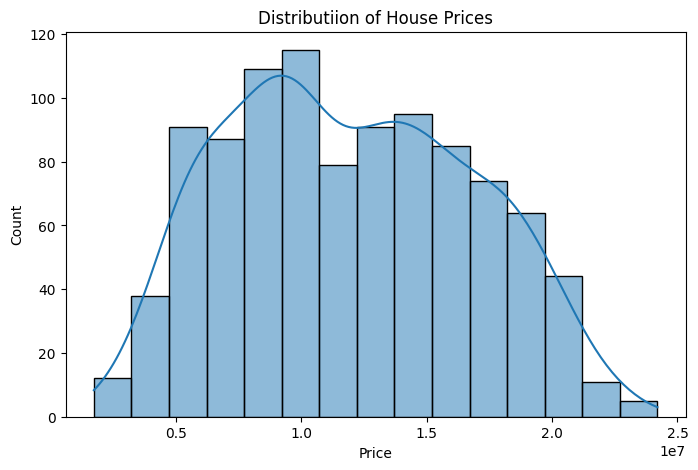

In [11]:
# house price prediction
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="Price",kde=True)
plt.title("Distributiion of House Prices")
plt.xlabel("Price")
plt.show()

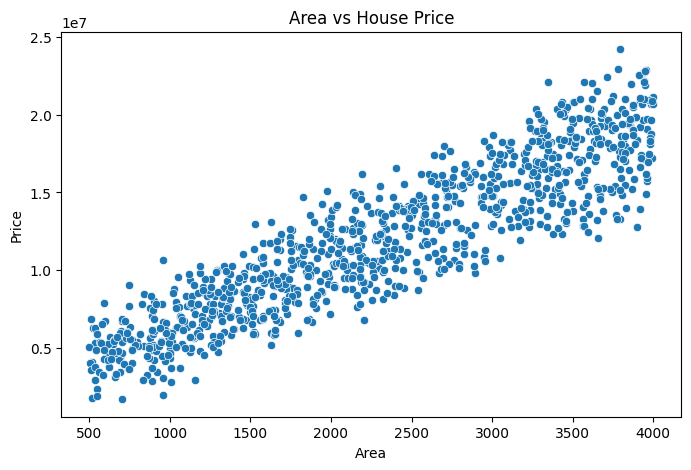

In [12]:
# Area vs price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="Area",y="Price")
plt.title("Area vs House Price")
plt.show()

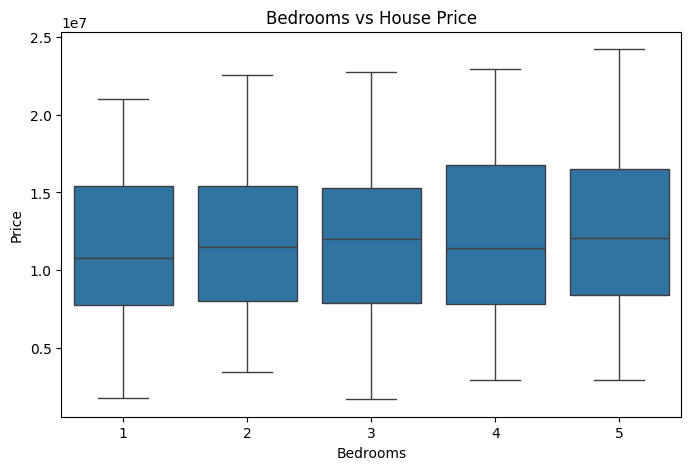

In [13]:
# Bedrooms vs Price
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="Bedrooms",y="Price")
plt.title("Bedrooms vs House Price")
plt.show()

Text(0.5, 1.0, 'Average House Price by Location')

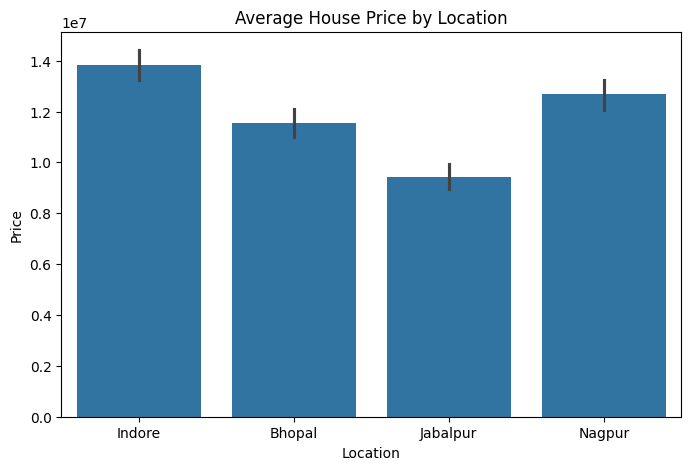

In [14]:
# Location vs Price
plt.figure(figsize=(8,5))
sns.barplot(data=df,x="Location",y="Price")
plt.title("Average House Price by Location")

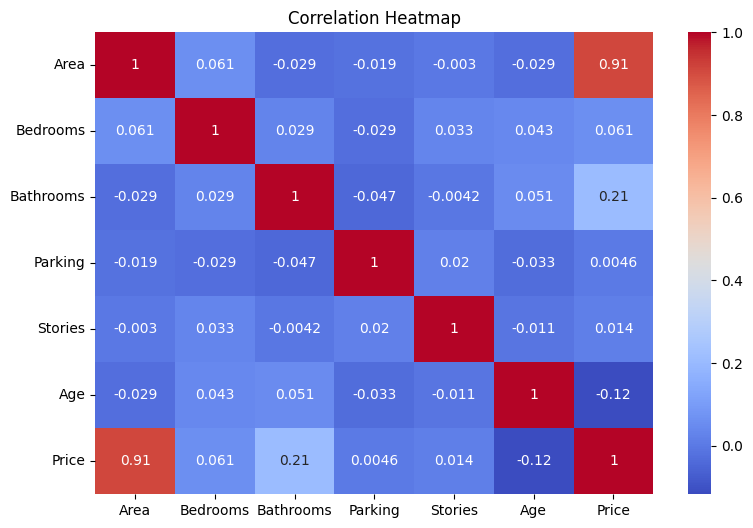

In [15]:
# Correlation Heatmap
plt.figure(figsize=(9,6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

### Data Preprocessing

In [16]:
df=df.drop_duplicates().copy()
print(df.isnull().sum())

Area          0
Bedrooms      0
Bathrooms     0
Parking       0
Stories       0
Location      0
Furnishing    0
Age           0
Price         0
dtype: int64


### FEATURE ENGINEERING

In [17]:
df["House_Age"]=df["Age"]

df["Total_Rooms"]=(
    df["Bedrooms"] + df["Bathrooms"]
)
df["Area_per_Bedroom"]=(
    df["Area"]/df["Bedrooms"]
)
def area_category(area):
    if area<1000:
        return "Small"
    elif area<2000:
        return "Medium"
    else:
        return "Large"
df["Area_Category"]=df["Area"].apply(area_category)

df.head()
   

,Area,Bedrooms,Bathrooms,Parking,Stories,Location,Furnishing,Age,Price,House_Age,Total_Rooms,Area_per_Bedroom,Area_Category
0,3674,2,1,2,2,Indore,Semi-Furnished,12,1.980523e+07,12,3,1837.00,Large
1,1360,1,2,2,2,Bhopal,Unfurnished,7,9.019109e+06,7,3,1360.00,Medium
2,1794,2,1,0,2,Jabalpur,Semi-Furnished,22,5.993878e+06,22,3,897.00,Medium
3,1630,1,1,1,3,Jabalpur,Unfurnished,15,5.990468e+06,15,2,1630.00,Medium
4,1595,4,2,2,2,Indore,Unfurnished,12,9.792379e+06,12,6,398.75,Medium


In [18]:
X=df.drop("Price",axis=1)
y=df["Price"]

### TRAIN TEST SPLIT

In [19]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

Training data: (800, 12)
Testing data: (200, 12)


### PREPROCESSING

In [20]:
numeric_features=[
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Parking",
    "Stories",
    "Age",
    "House_Age",
    "Total_Rooms",
    "Area_per_Bedroom"
    ]
categorical_features=["Location",
                      "Furnishing",
                      "Area_Category"

]
numeric_transformer=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
categorical_transformer=Pipeline([
   ( "imputer",SimpleImputer(strategy="most_frequent")),
   ("encoder",OneHotEncoder(handle_unknown="ignore"))
])
preprocessor=ColumnTransformer([
    ("num",numeric_transformer,numeric_features),
    ("cat",categorical_transformer,categorical_features)
])


### MODEL TRAINING

In [21]:
lr_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LinearRegression())
])
lr_model.fit(X_train,y_train)
lr_predictions=lr_model.predict(X_test)
print("Linear Regression trained")

Linear Regression trained


In [22]:
# Random forest
rf_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])
rf_model.fit(X_train,y_train)
rf_predictions=rf_model.predict(X_test)
print("Random Forest trained")

Random Forest trained


### MODEL EVALUATION

In [23]:
def evaluate_model(name,y_test,predictions):
    mae=mean_absolute_error(y_test,predictions)
    rmse=np.sqrt(mean_squared_error(y_test,predictions))
    r2=r2_score(y_test,predictions)

    print(f"\n{name}")
    print("MAE:",round(mae,2))
    print("RMSE",round(rmse,2))
    print("R2 Score",round(r2,4))

evaluate_model("Linear REgression",y_test,lr_predictions)
evaluate_model("Random Forest",y_test,rf_predictions)


Linear REgression
MAE: 549025.56
RMSE 733496.58
R2 Score 0.9771

Random Forest
MAE: 639022.87
RMSE 784189.01
R2 Score 0.9739


### BEST MODEL

In [24]:
lr_r2=r2_score(y_test,lr_predictions)
rf_r2=r2_score(y_test,rf_predictions)
if rf_r2>=lr_r2:
    best_model=rf_model
    print("Selected: Random Forest")
else:
    best_model=lr_model
    print("Selected: Linear Regression")

joblib.dump(best_model,"house_price-model.pkl")

print("Model saved successfully")

Selected: Linear Regression
Model saved successfully


### NEW HOUSE PRICE PREDICTION

In [25]:
new_house=pd.DataFrame({
    "Area":[1500],
    "Bedrooms":[3],
    "Bathrooms":[2],
    "Parking":[1],
    "Stories":[2],
    "Location":["jabalpur"],
    "Furnishing":["Semi-Furnished"],
    "Age":[5],
    "House_Age":[5],
    "Total_Rooms":[5],
    "Area_per_Bedroom":[500],
    "Area_Category":["Medium"]                  
})
loaded_model=joblib.load("house_price-model.pkl")

predicted_price=loaded_model.predict(new_house)[0]

print(f"Predicted House Price:{predicted_price:,.0f}")


Predicted House Price:8,640,635
